[![Roboflow Notebooks](https://media.roboflow.com/notebooks/template/bannertest2-2.png?ik-sdk-version=javascript-1.4.3&updatedAt=1672932710194)](https://github.com/roboflow/notebooks)

# How to Train YOLO26 Object Detection on a Custom Dataset

---

[![roboflow](https://raw.githubusercontent.com/roboflow-ai/notebooks/main/assets/badges/roboflow-blogpost.svg)](https://blog.roboflow.com/how-to-train-yolo26-custom-data/) [![GitHub](https://badges.aleen42.com/src/github.svg)](https://github.com/ultralytics/ultralytics)

YOLO26 introduces a unified architecture designed to support detection, segmentation, and pose tasks within a single model family. The model uses an anchor-free design with a decoupled head.

## Setup

In [1]:
!pip install roboflow


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 103.9 MB/s  0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [roboflow]


In [2]:

from roboflow import Roboflow
rf = Roboflow(api_key="1zaBHQwceQYKIpq0yKki")
project = rf.workspace("manar-nqk6x").project("pcb-defect-detection-9ewqw-rzuwm")
version = project.version(1)
dataset = version.download("yolo26")


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to pcb-defect-detection-1 in yolo26:: 100%|██████████| 3471/3471 [00:03<00:00, 1038.86it/s]


In [3]:
!pip install -q ultralytics

In [4]:
from ultralytics import YOLO

model = YOLO("yolo26s.pt")

results = model.train(
    data=f"{dataset.location}/data.yaml",
    epochs=80,

    batch=16,
    patience=20,
    project="pcb_project",
    name="yolo26s_exp1",
    device=0
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/pcb-defect-detection-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fr

In [5]:
from ultralytics import YOLO


best_model = YOLO("/content/runs/detect/pcb_project/yolo26s_exp1/weights/best.pt")

metrics = best_model.val(
    data="/content/pcb-defect-detection-1/data.yaml",
    split="test",
    plots=True
)


print(f"mAP@50:      {metrics.box.map50:.4f}")
print(f"mAP@50-95:   {metrics.box.map:.4f}")
print(f"Precision:   {metrics.box.mp:.4f}")
print(f"Recall:      {metrics.box.mr:.4f}")

Ultralytics 8.4.220 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26s summary (fused): 120 layers, 9,467,502 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 55.5±43.0 MB/s, size: 304.2 KB)
val: Scanning /content/pcb-defect-detection-1/test/labels... 69 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 69/69 217.1it/s 0.3s
val: New cache created: /content/pcb-defect-detection-1/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.6it/s 3.1s
                   all         69        292      0.961      0.908      0.952      0.511
          missing_hole         16         67      0.988      0.985      0.997      0.554
            mouse_bite         13         54      0.998      0.926      0.959      0.522
          open_circuit          9         32      0.927      0.906      0.914      0.527
                 short         11         52      0.981   

--- confusion_matrix.png ---


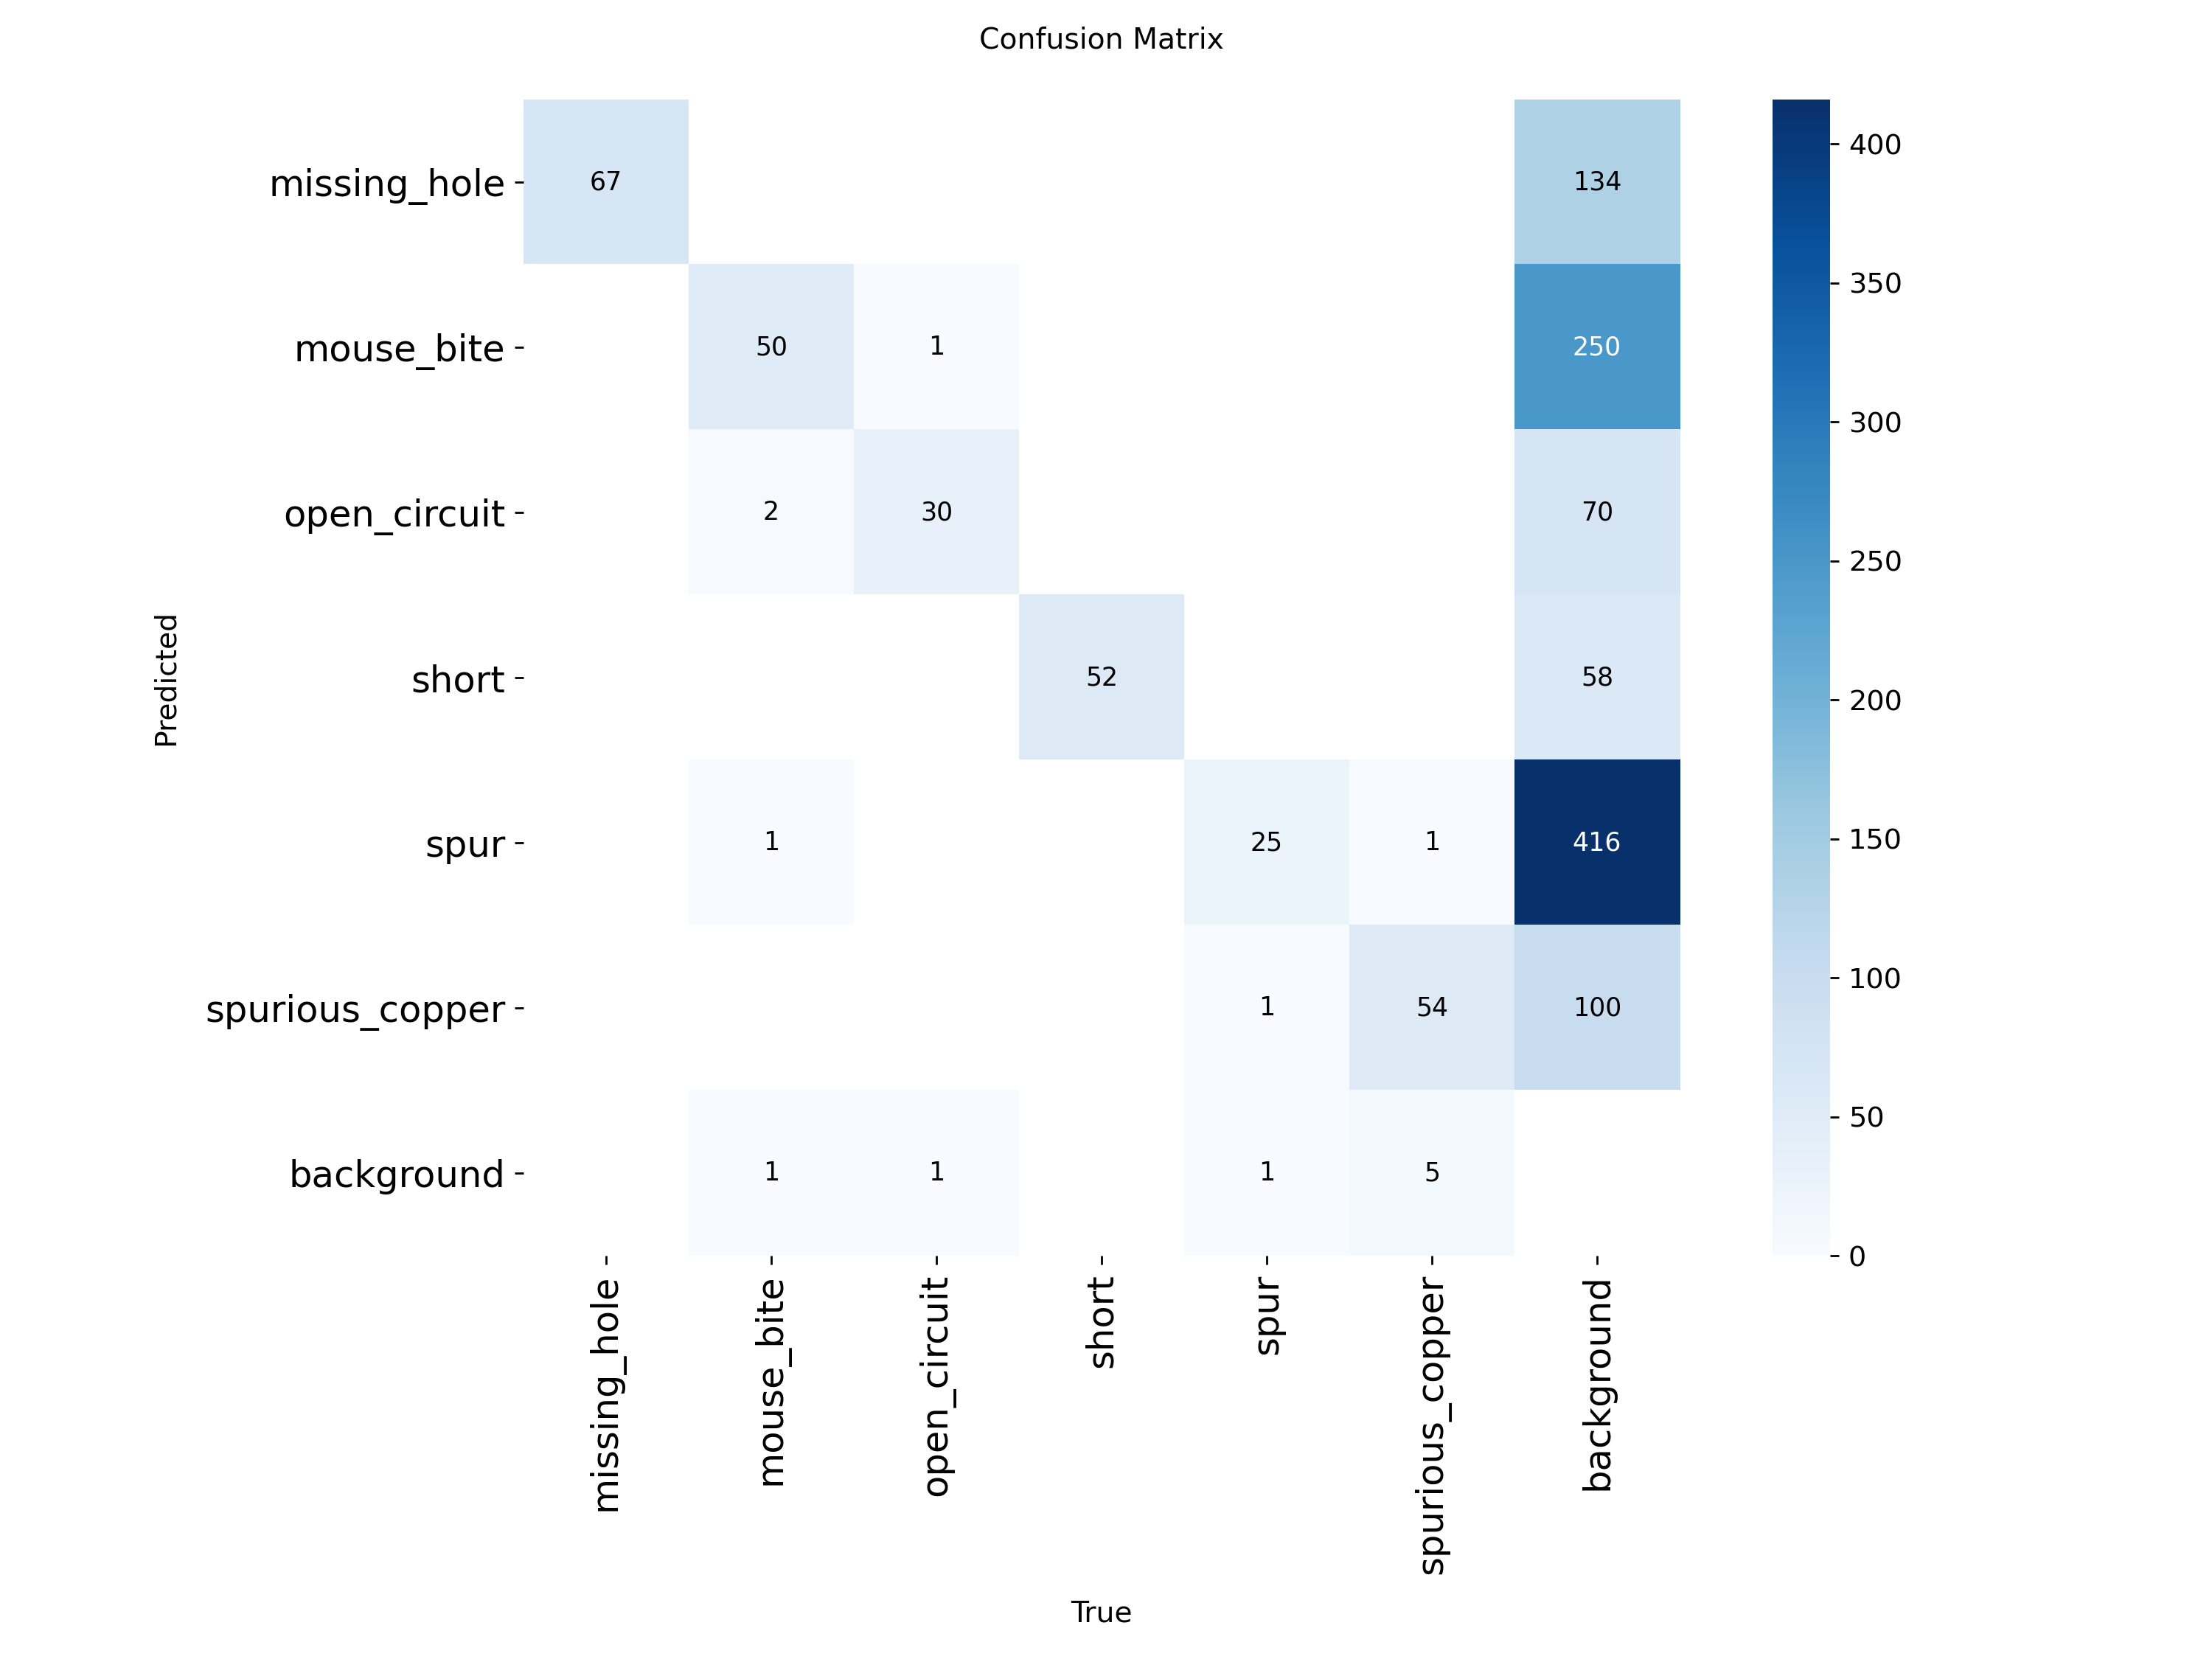

--- confusion_matrix_normalized.png ---


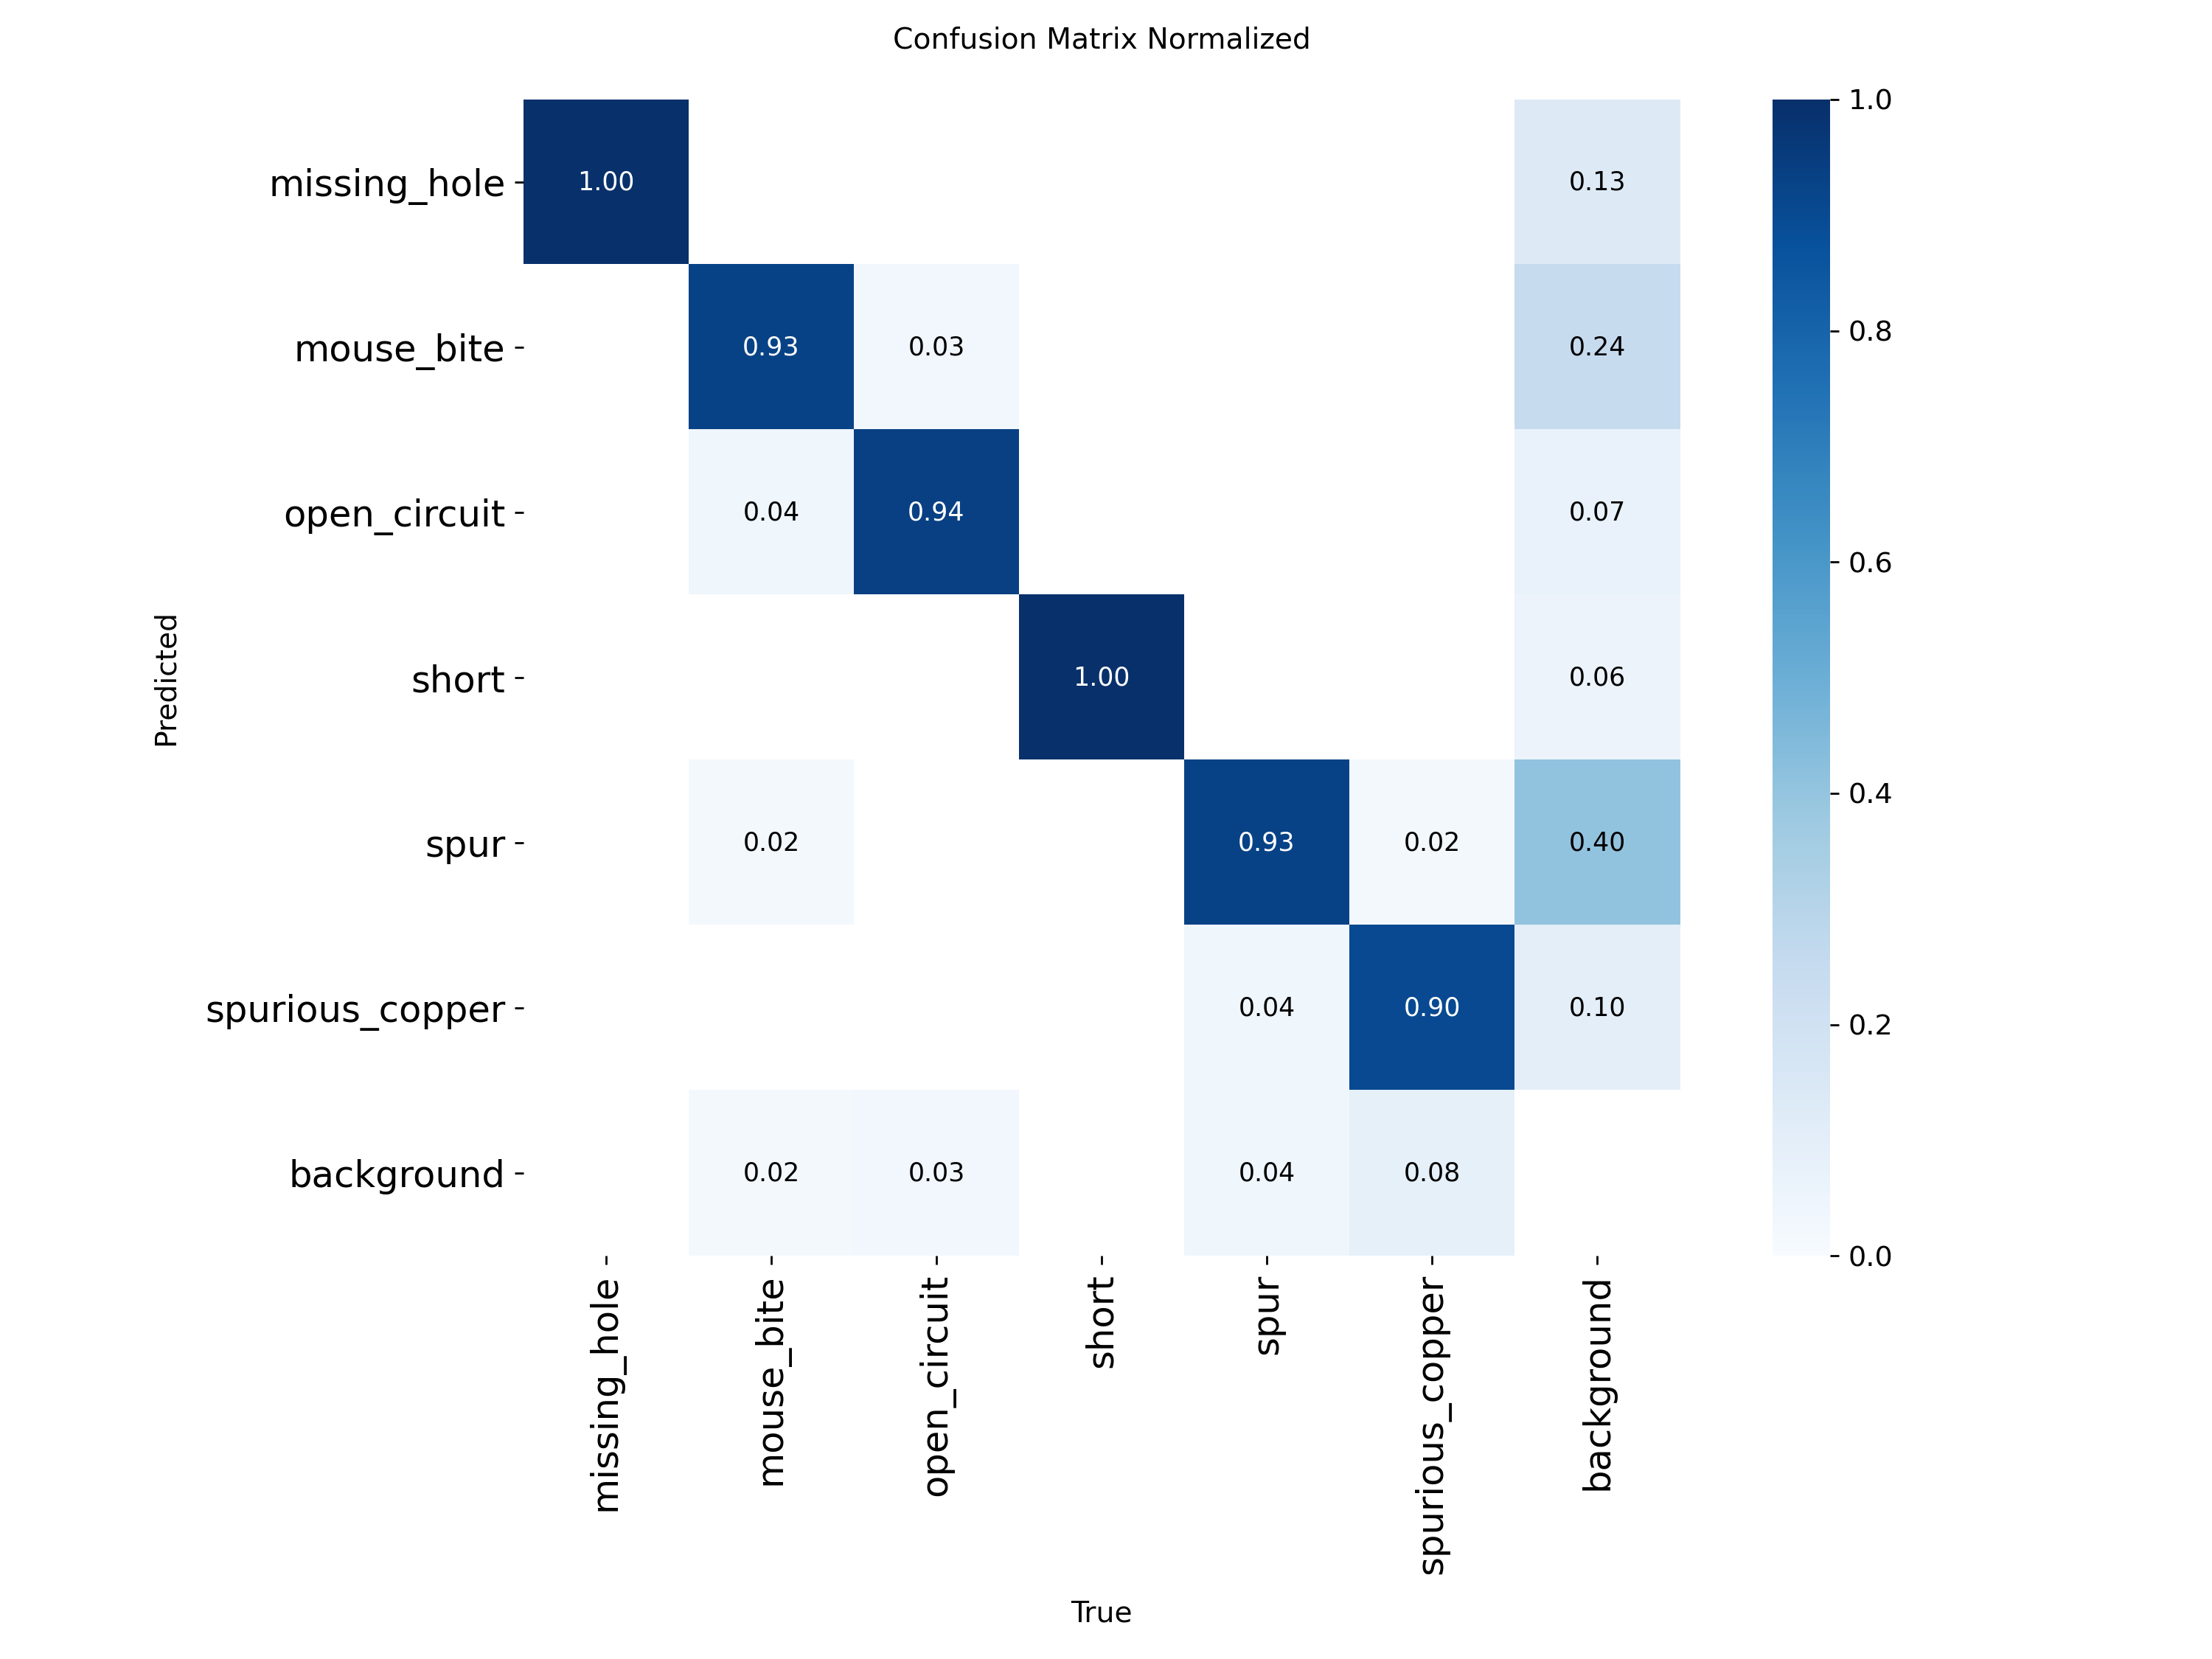

--- BoxPR_curve.png ---


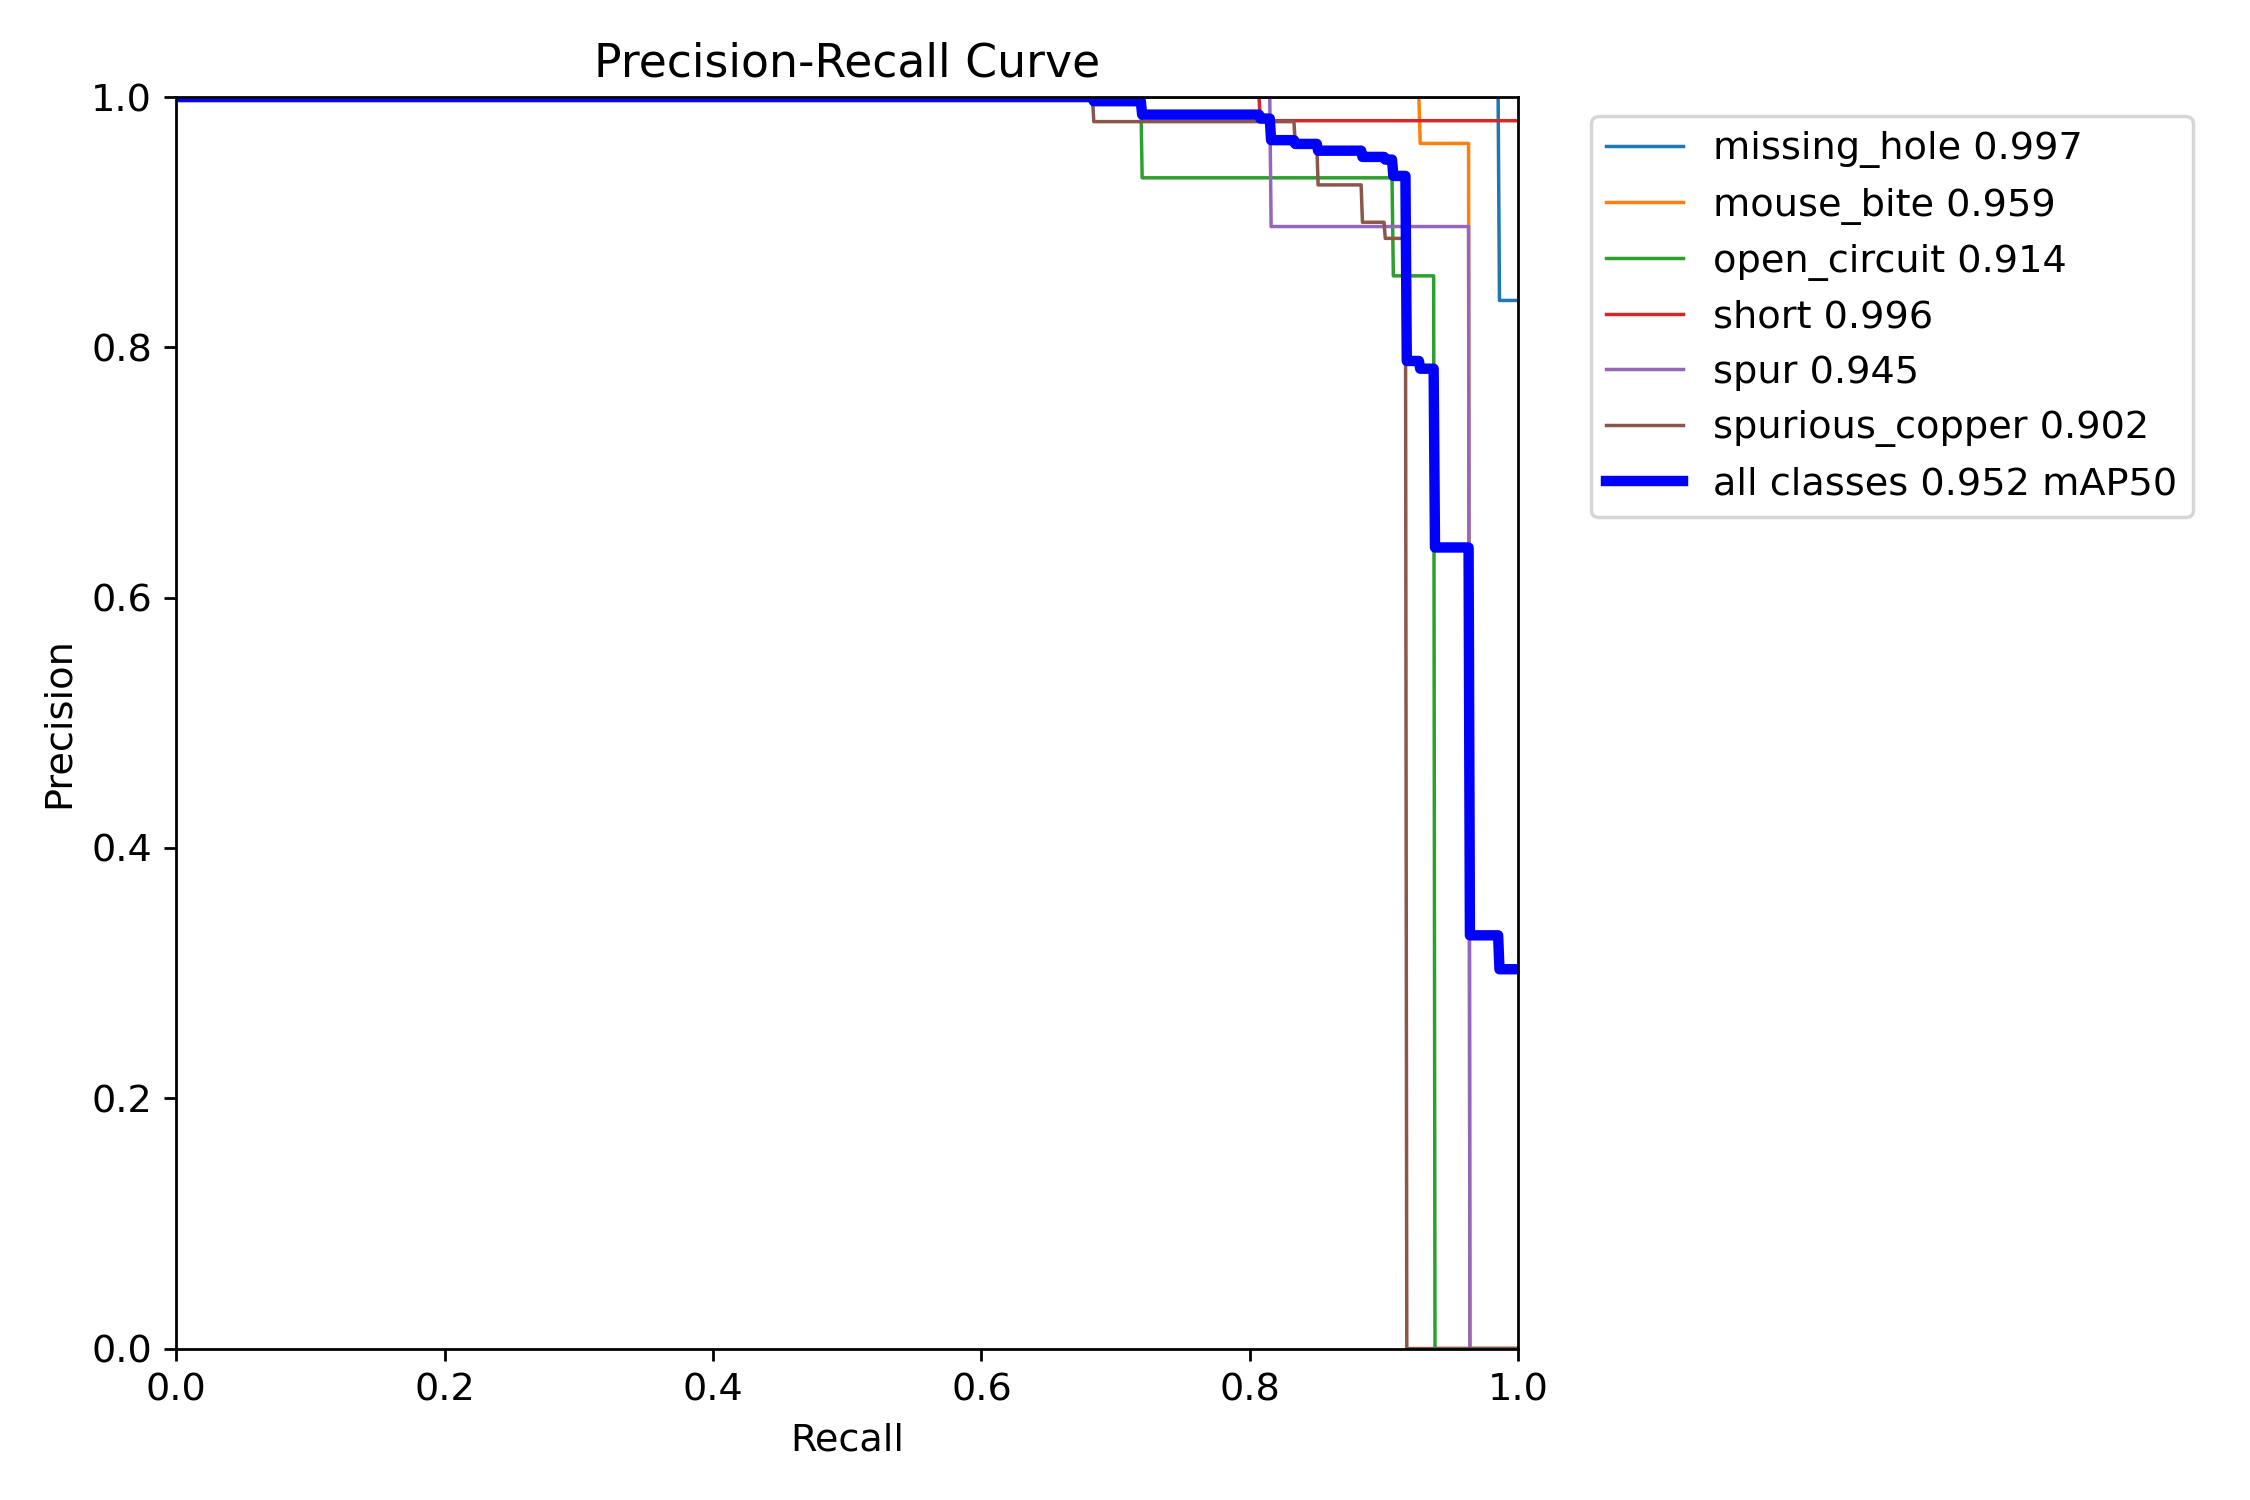

--- BoxF1_curve.png ---


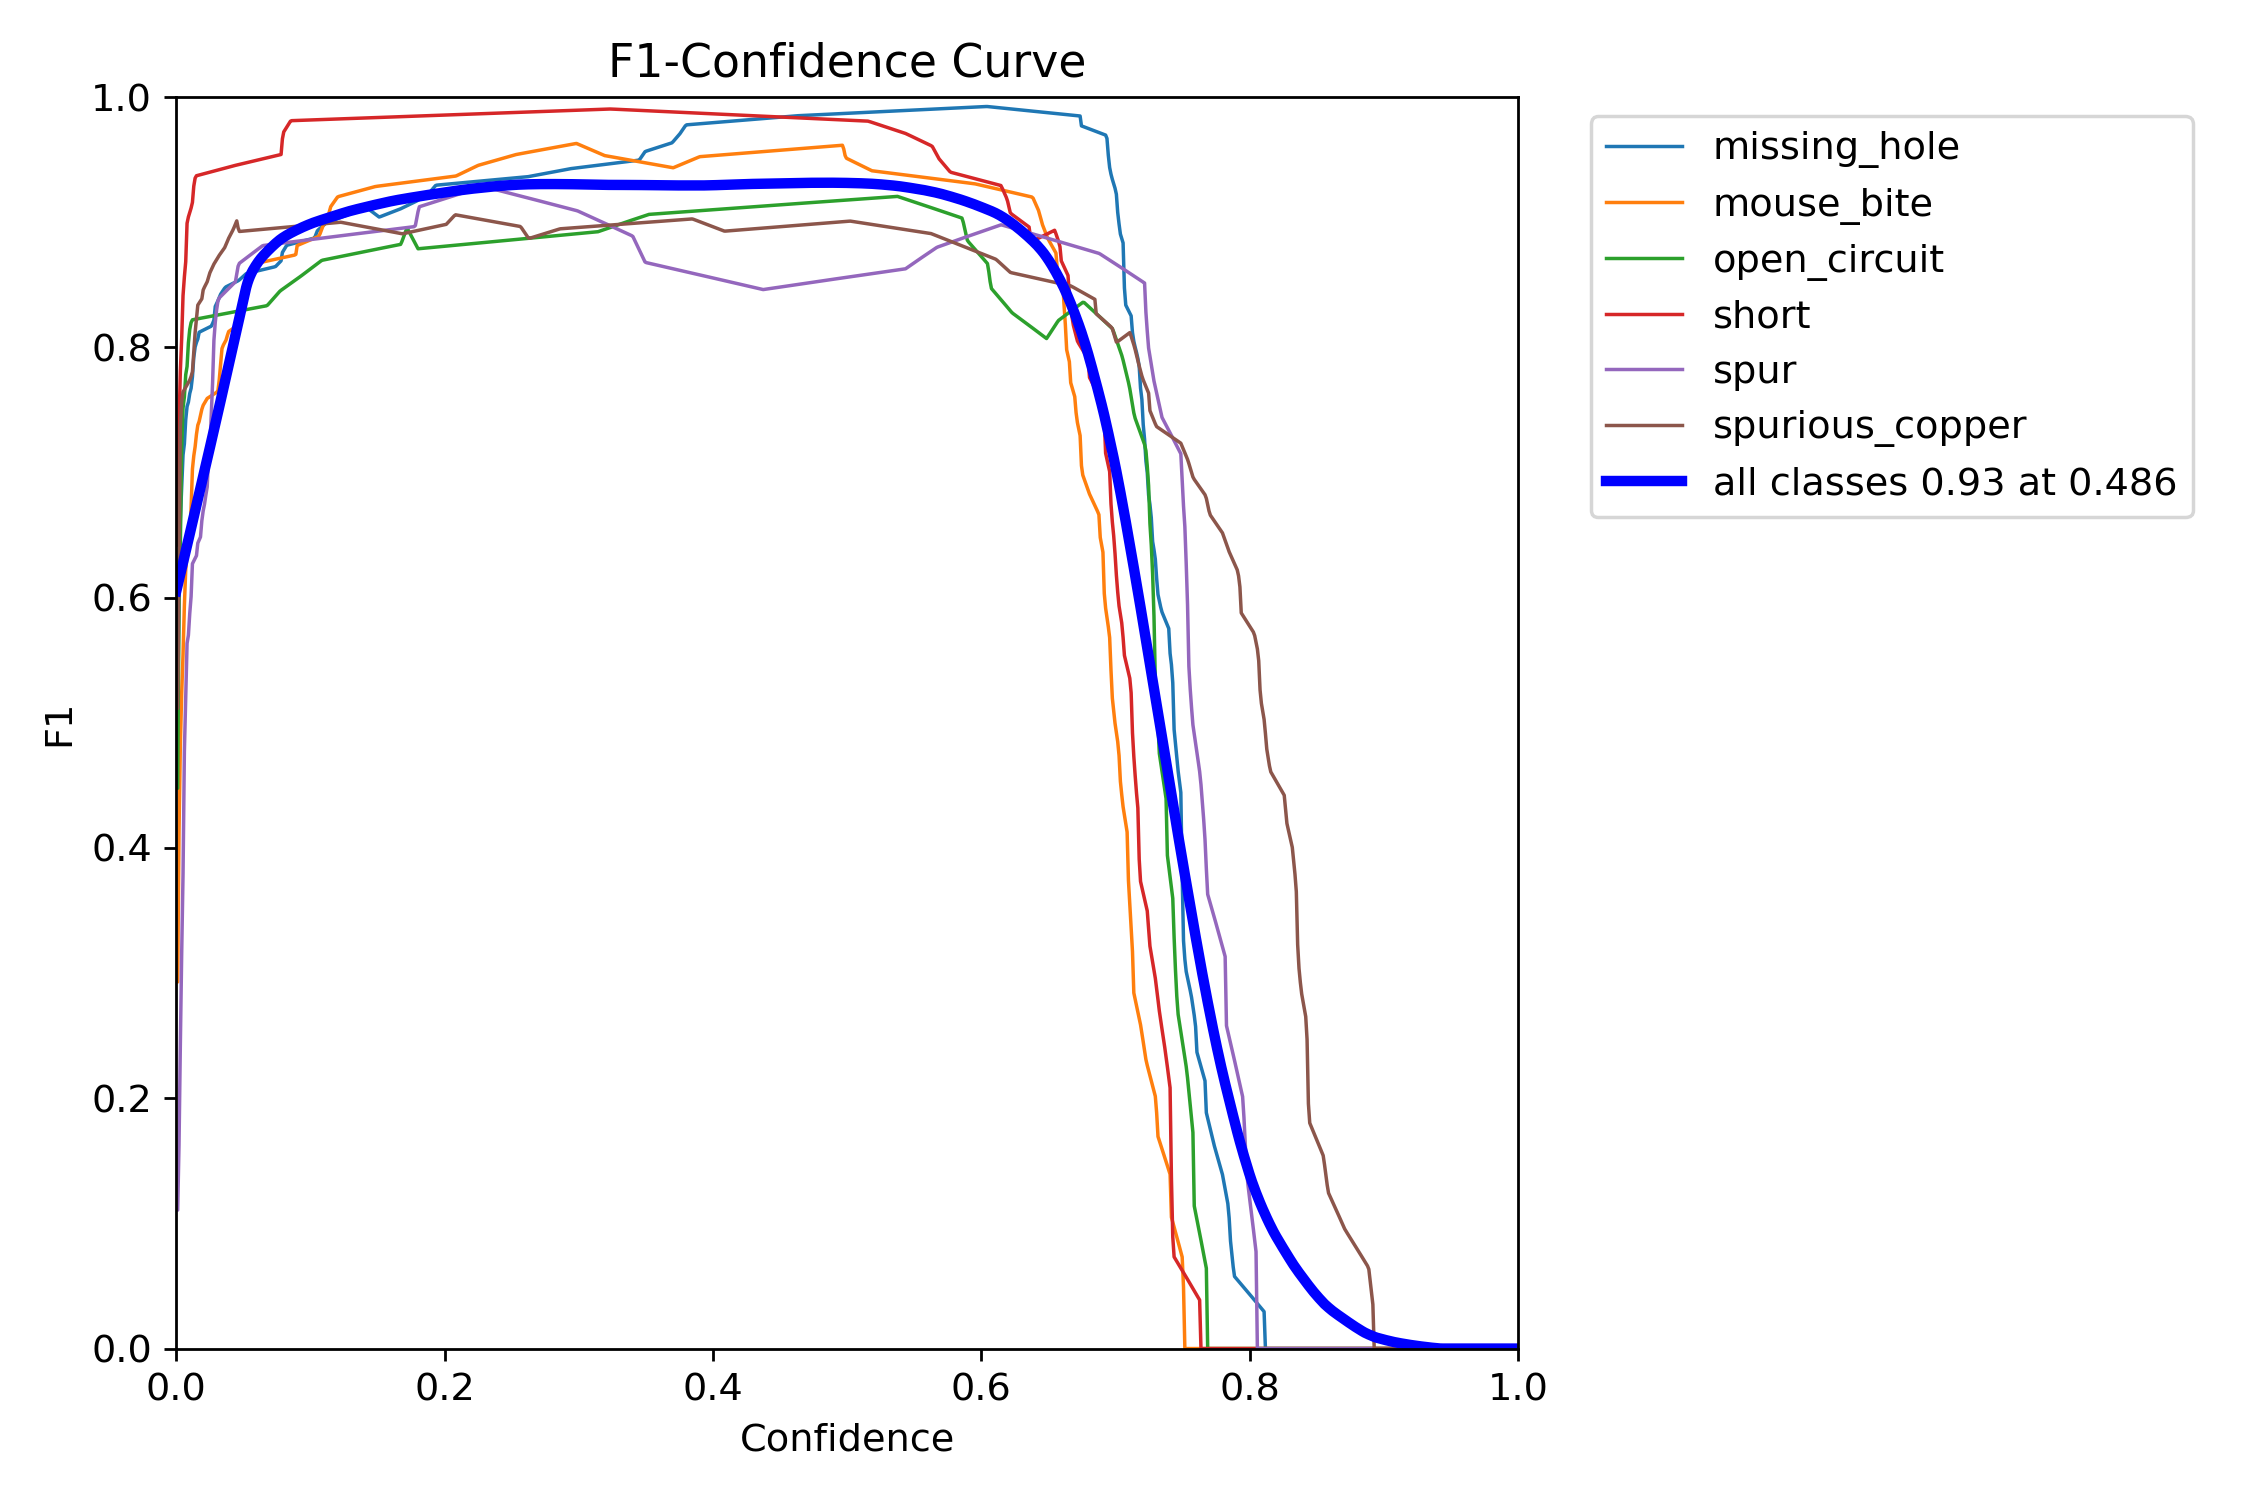

--- BoxP_curve.png ---


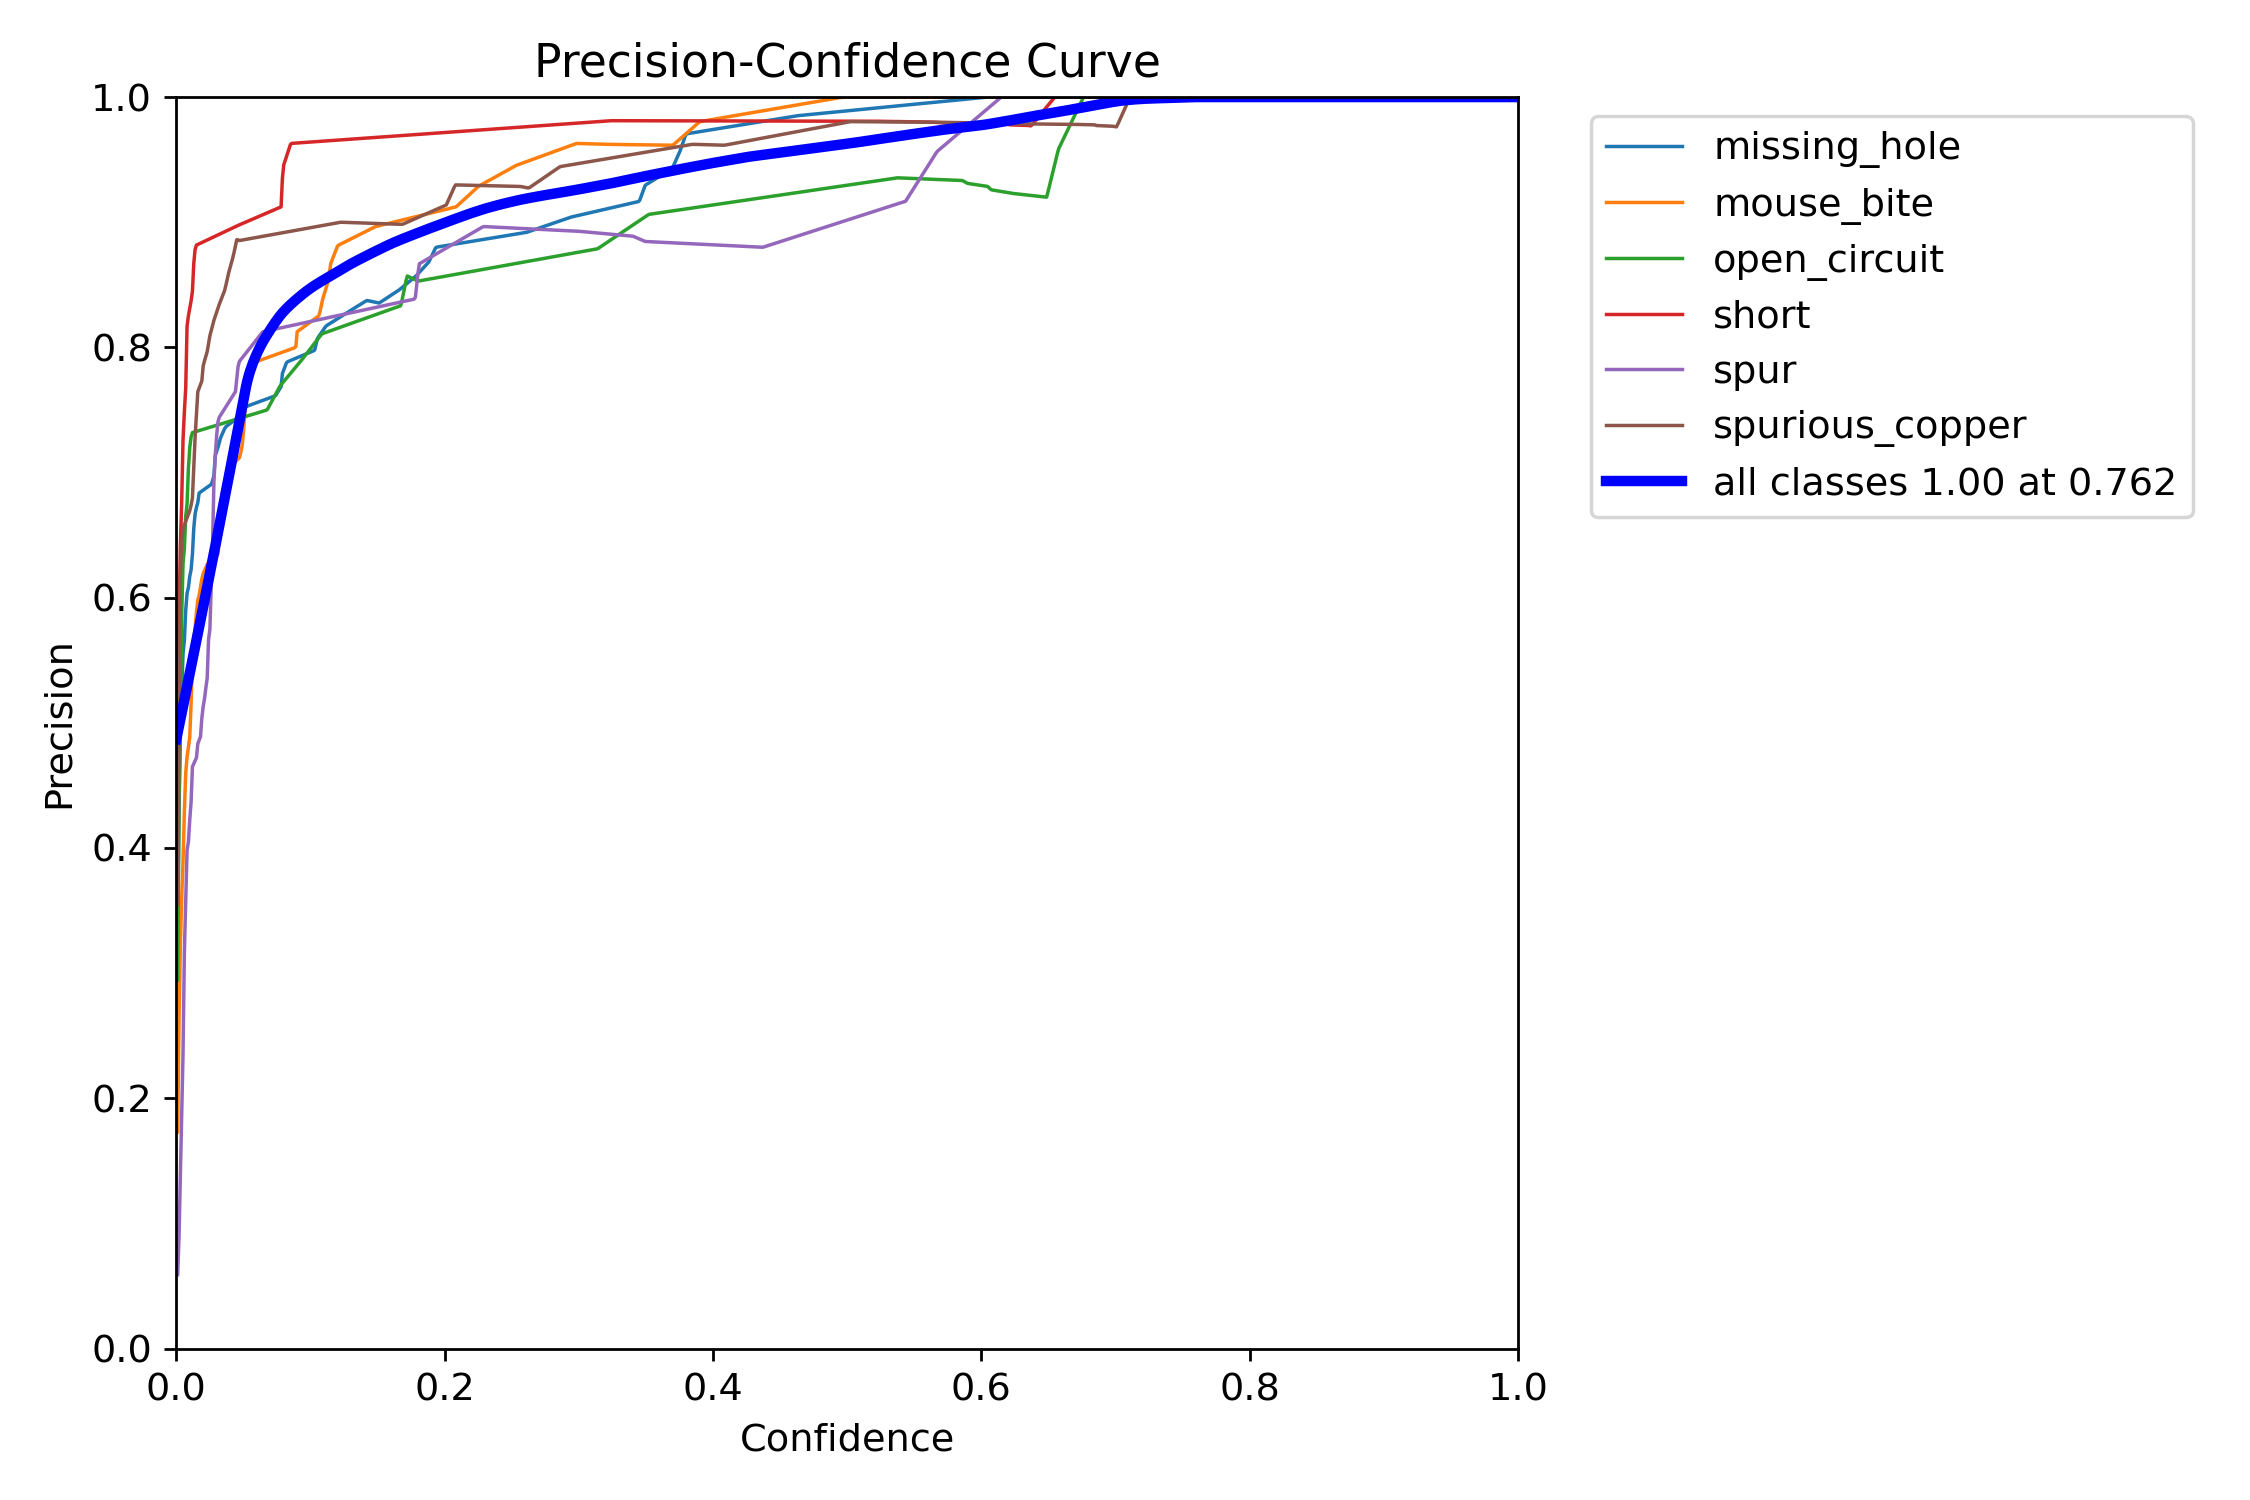

--- BoxR_curve.png ---


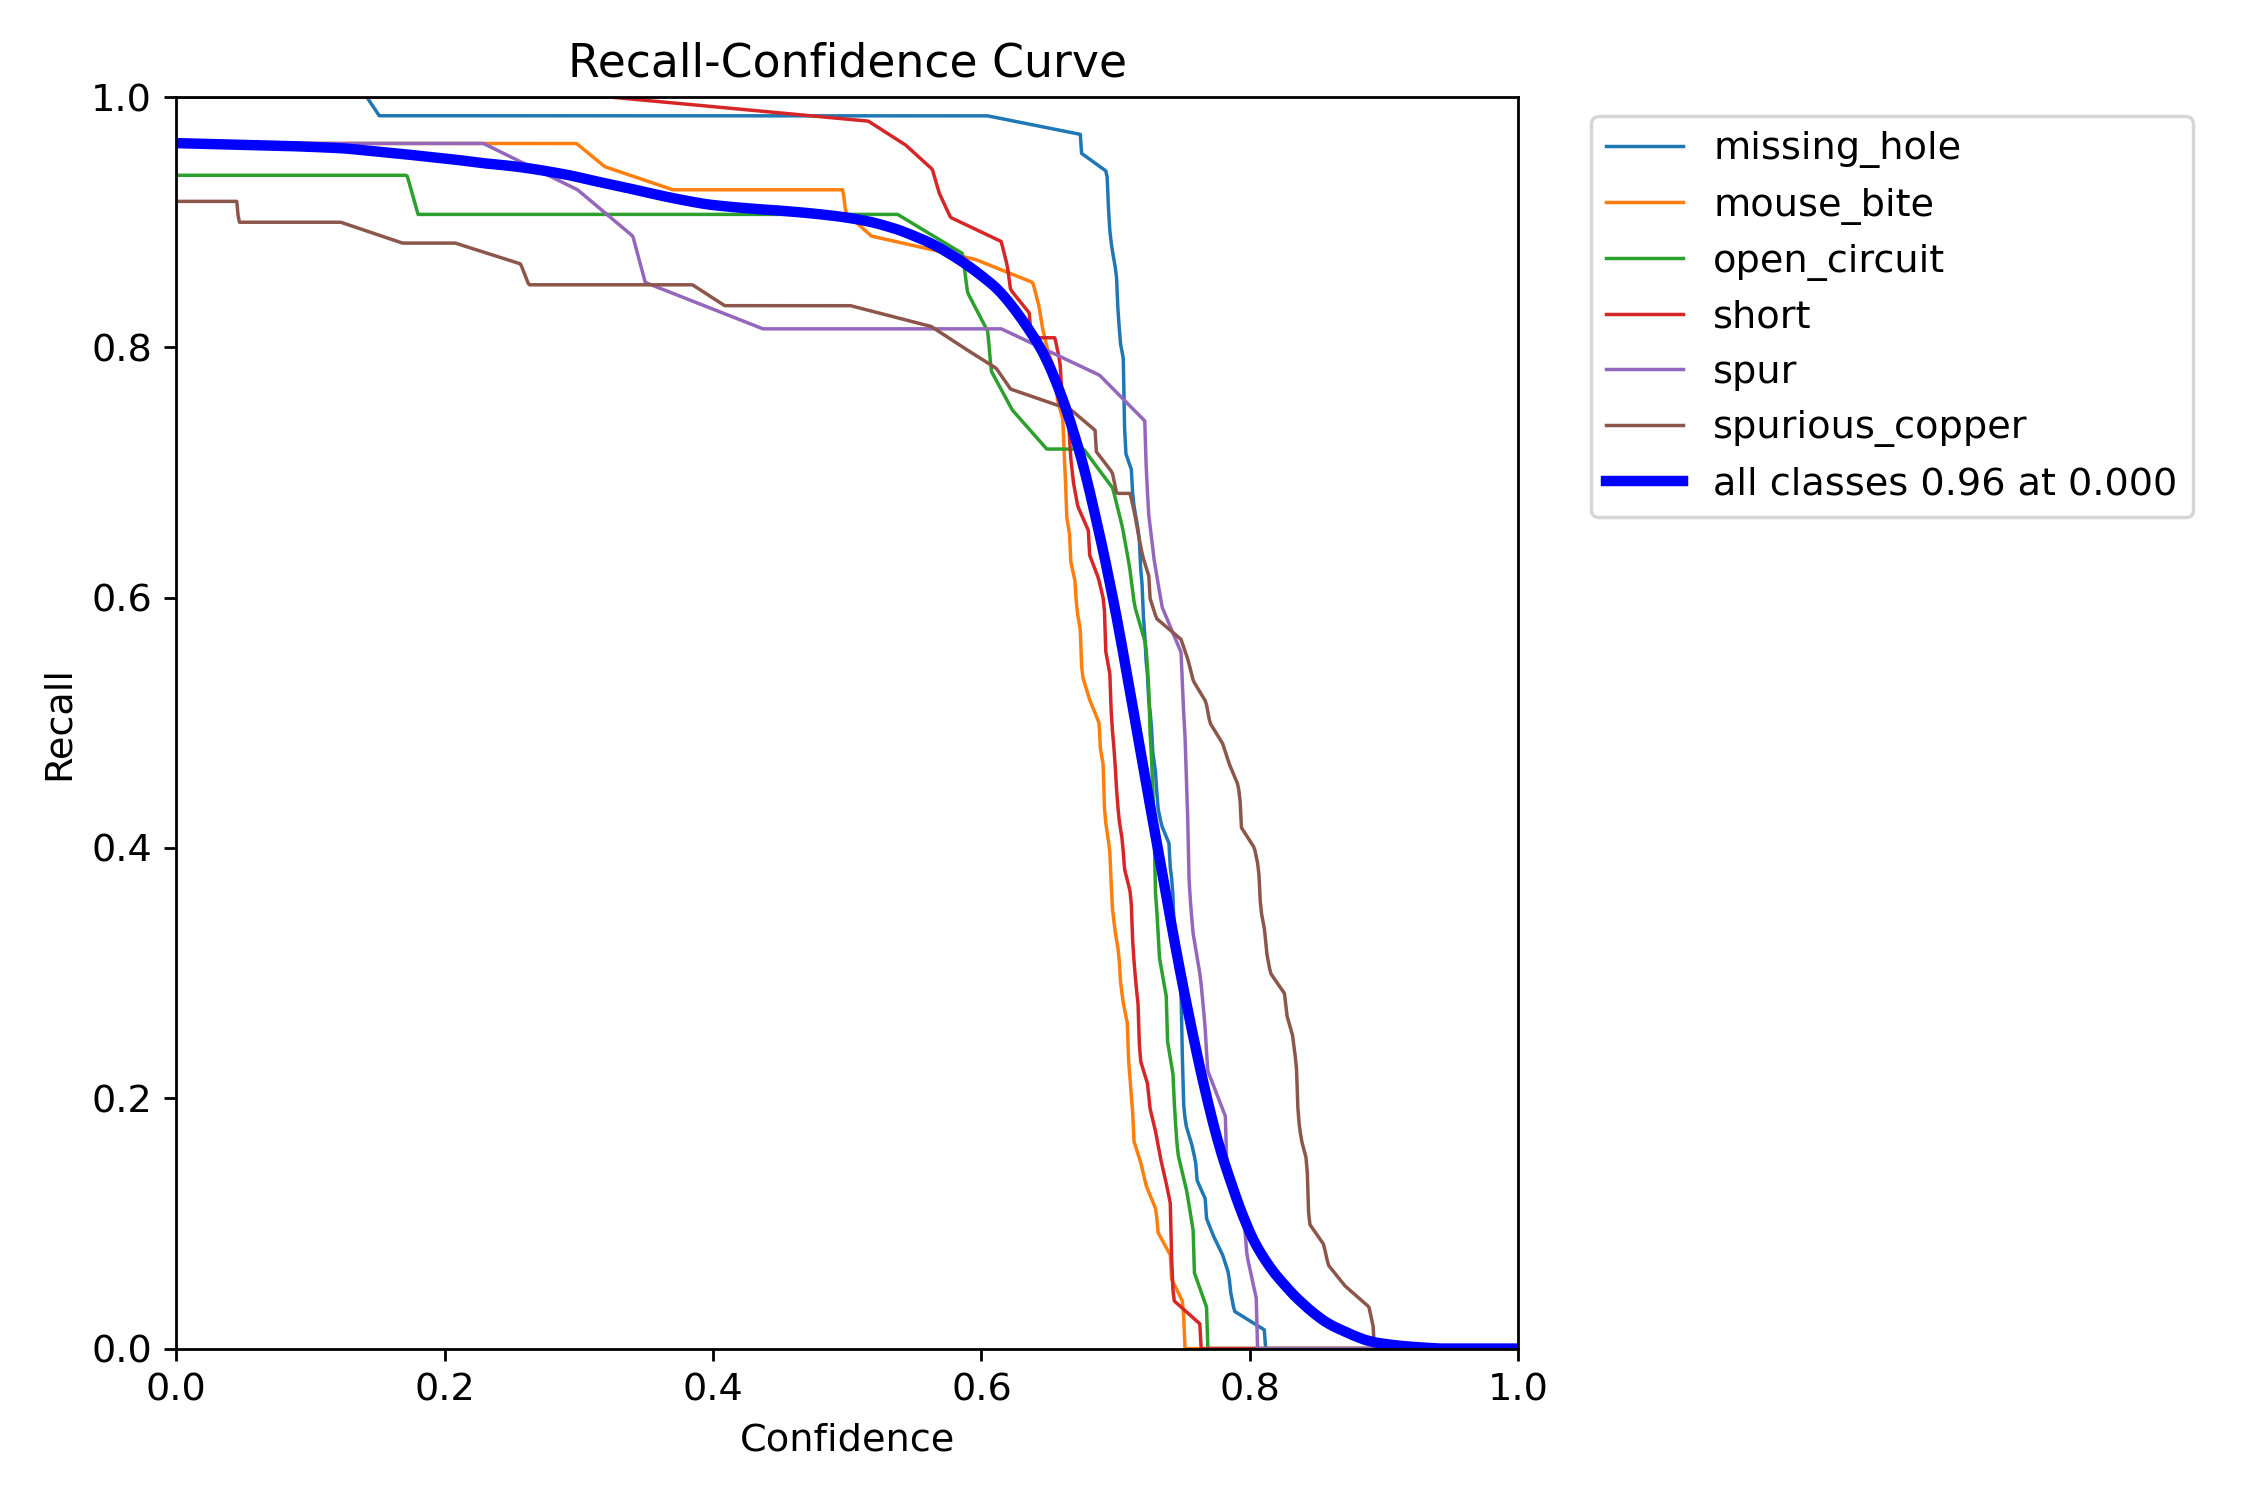

In [15]:
from IPython.display import Image, display
import glob
import os

eval_dirs = sorted(glob.glob("/content/runs/detect/val*"))
latest_eval = eval_dirs[-1]

img_names = [
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "BoxPR_curve.png",
    "BoxF1_curve.png",
    "BoxP_curve.png",
    "BoxR_curve.png",
]

for img_name in img_names:
    img_path = f"{latest_eval}/{img_name}"
    if os.path.exists(img_path):
        print(f"--- {img_name} ---")
        display(Image(filename=img_path, width=700))
    else:
        print(f"not found : {img_name}")


0: 640x640 5 missing_holes, 12.6ms
1: 640x640 2 mouse_bites, 12.6ms
2: 640x640 5 open_circuits, 12.6ms
3: 640x640 3 shorts, 12.6ms
4: 640x640 5 spurs, 12.6ms
5: 640x640 5 spurious_coppers, 12.6ms
Speed: 4.0ms preprocess, 12.6ms inference, 4.0ms postprocess per image at shape (1, 3, 640, 640)


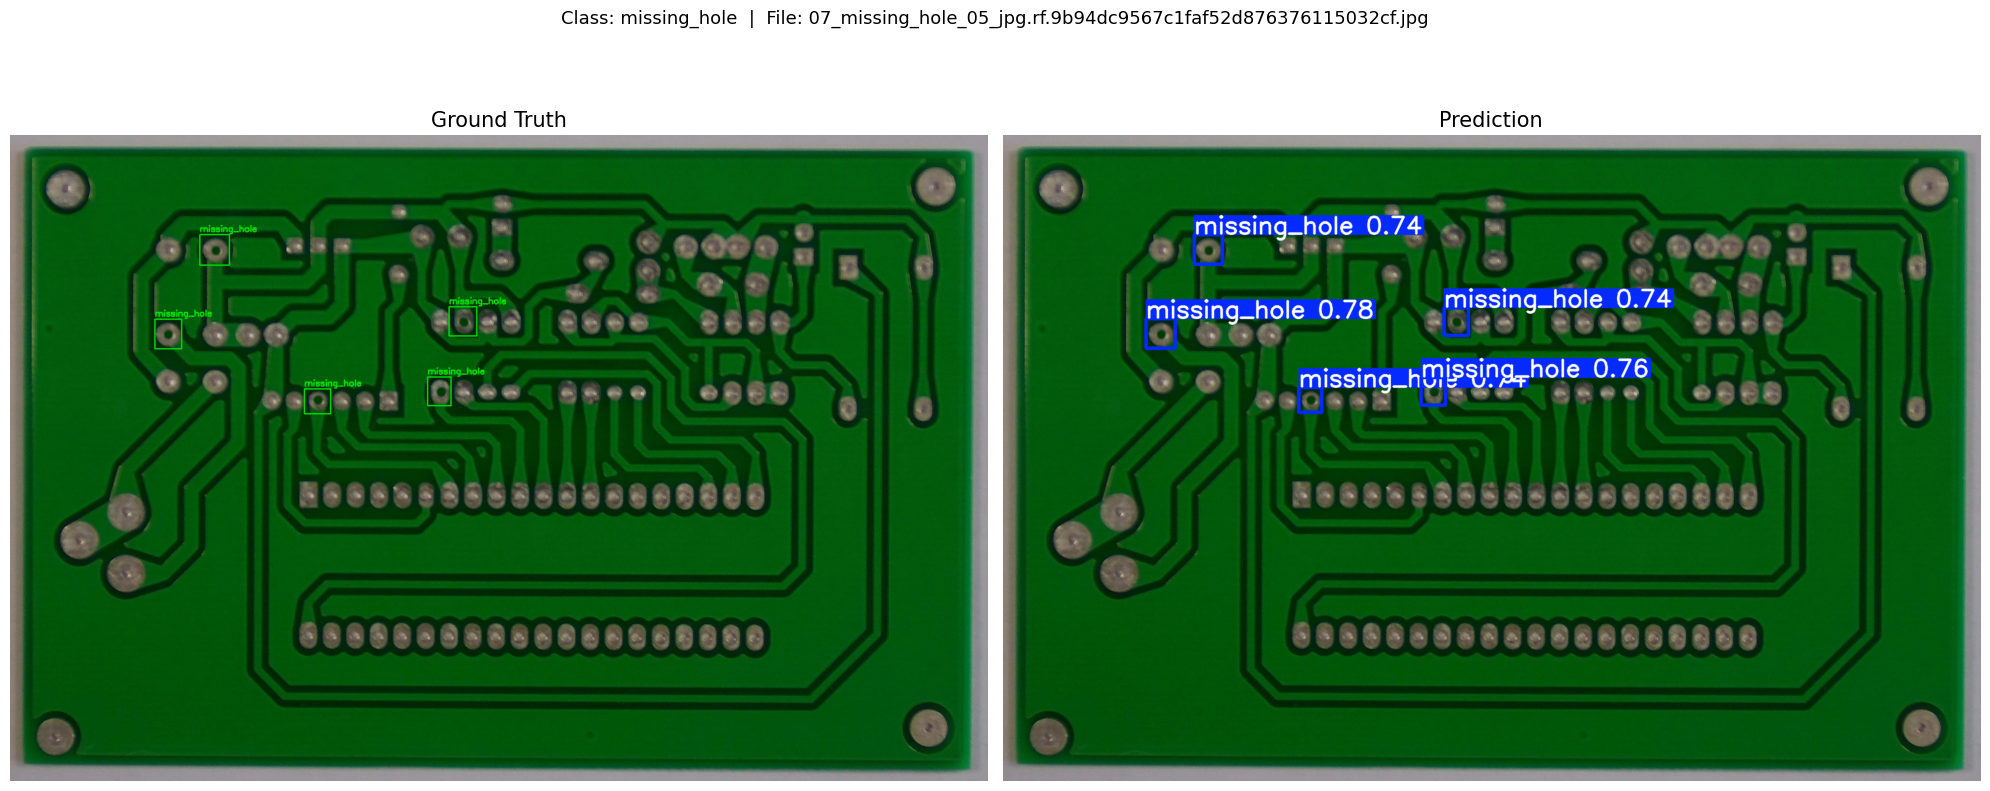

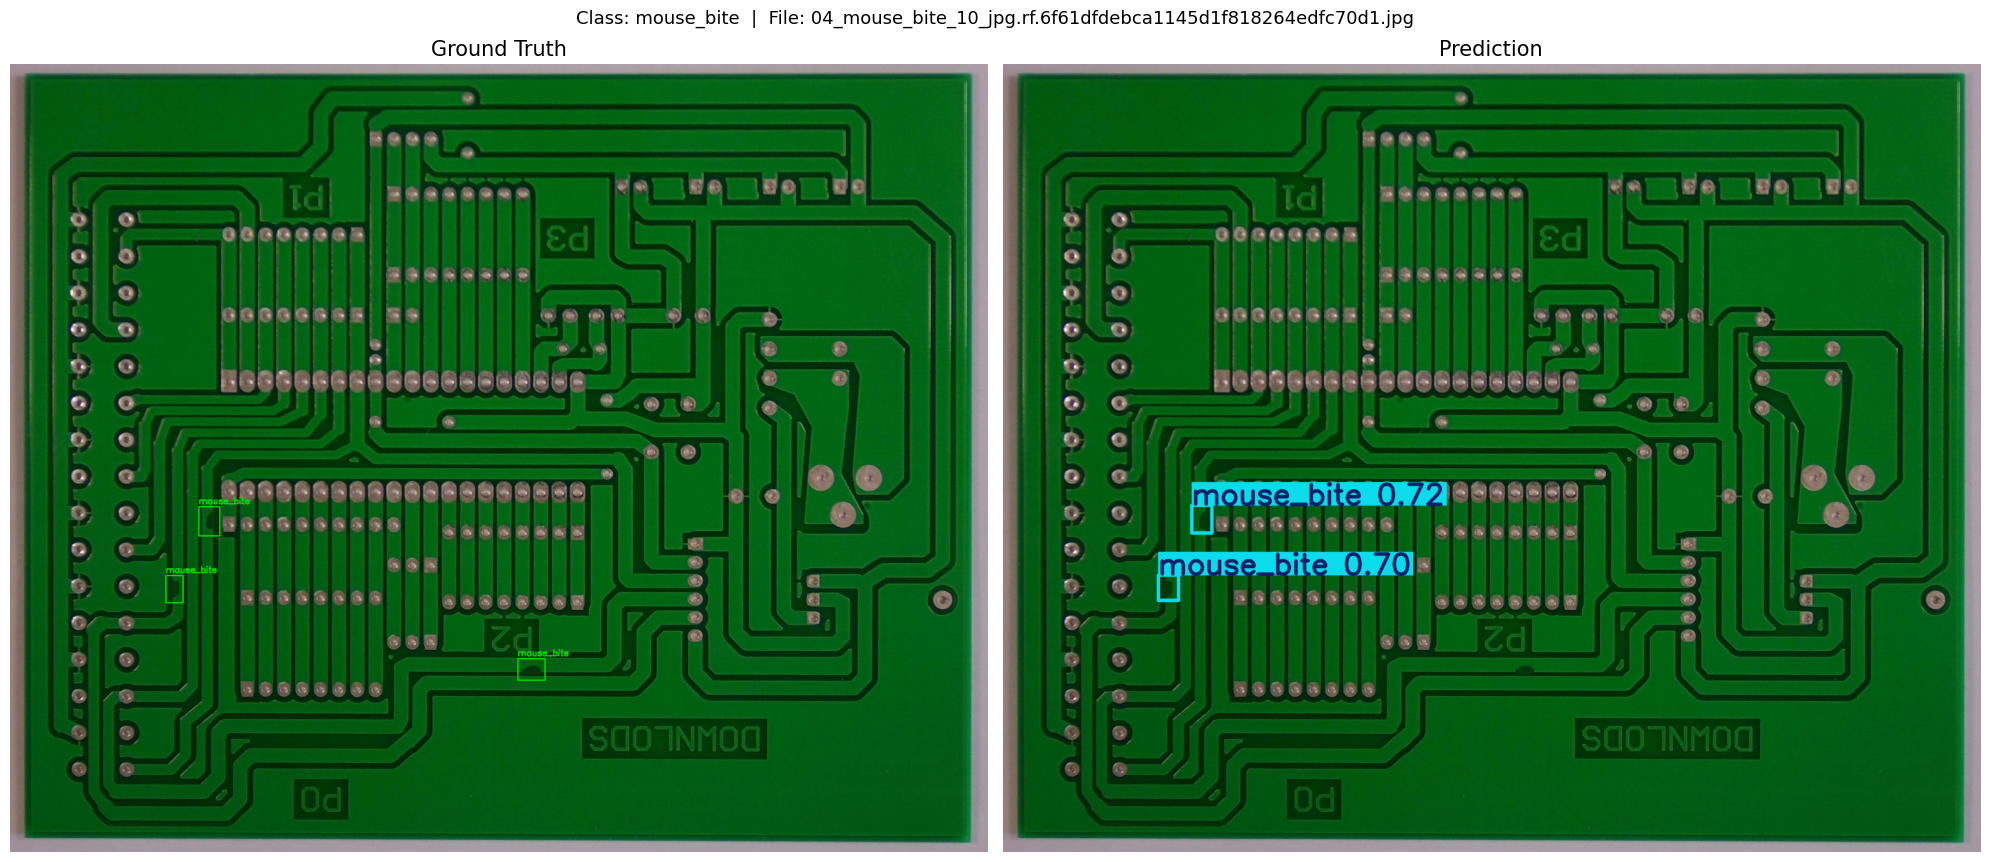

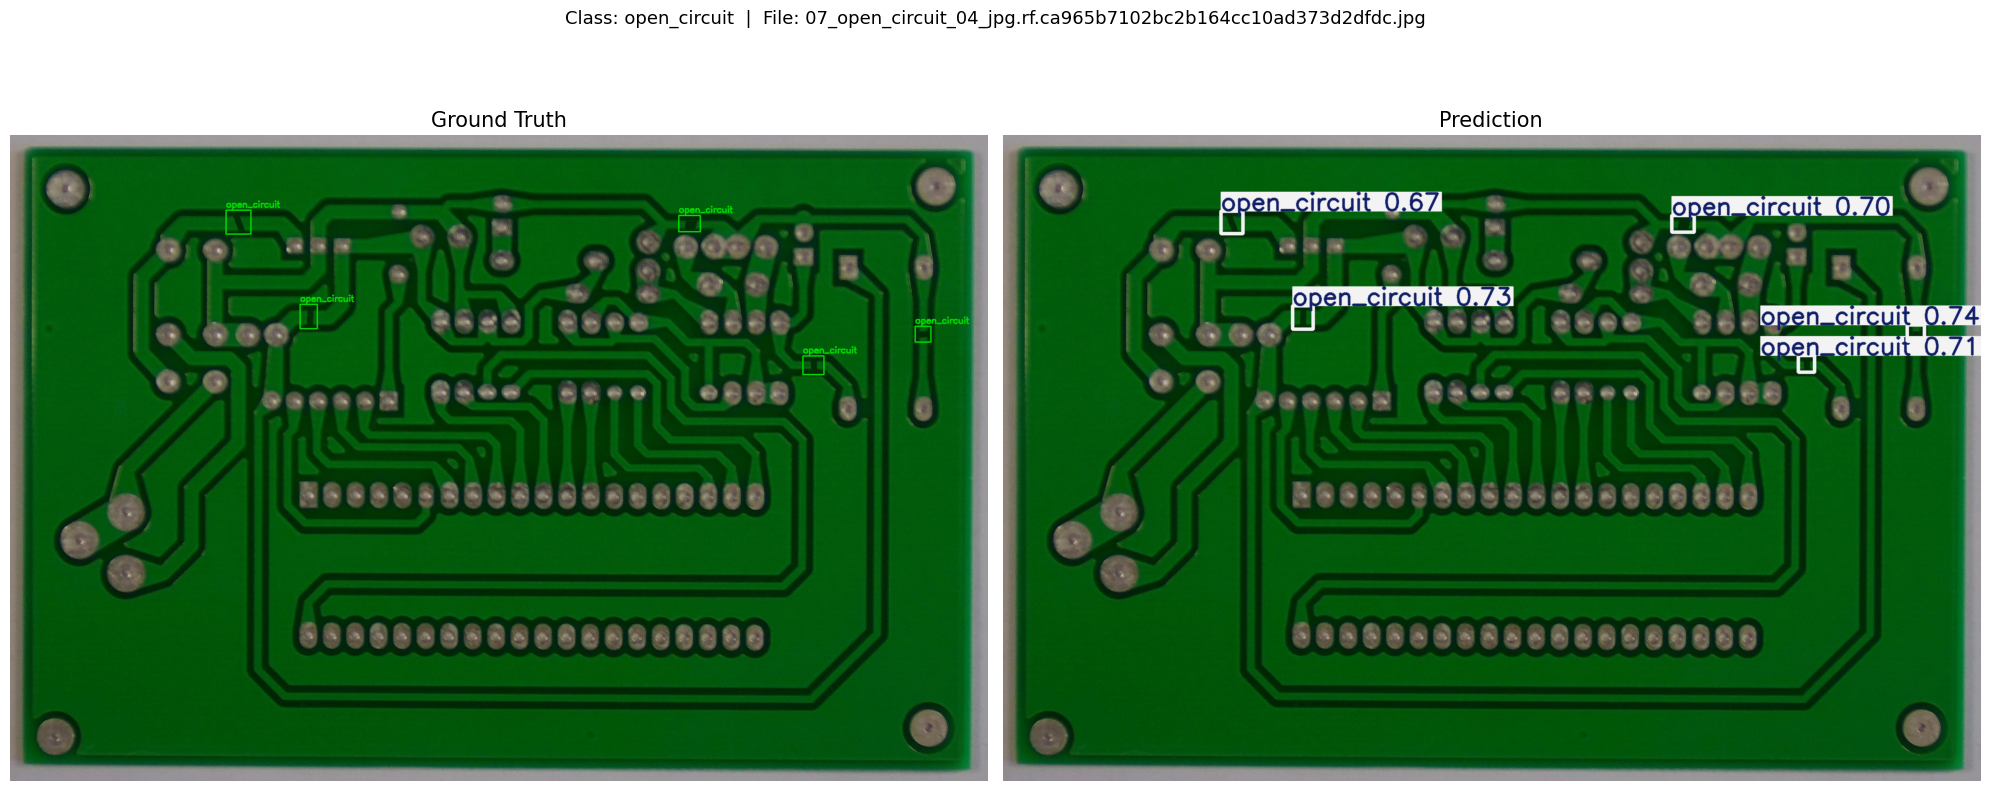

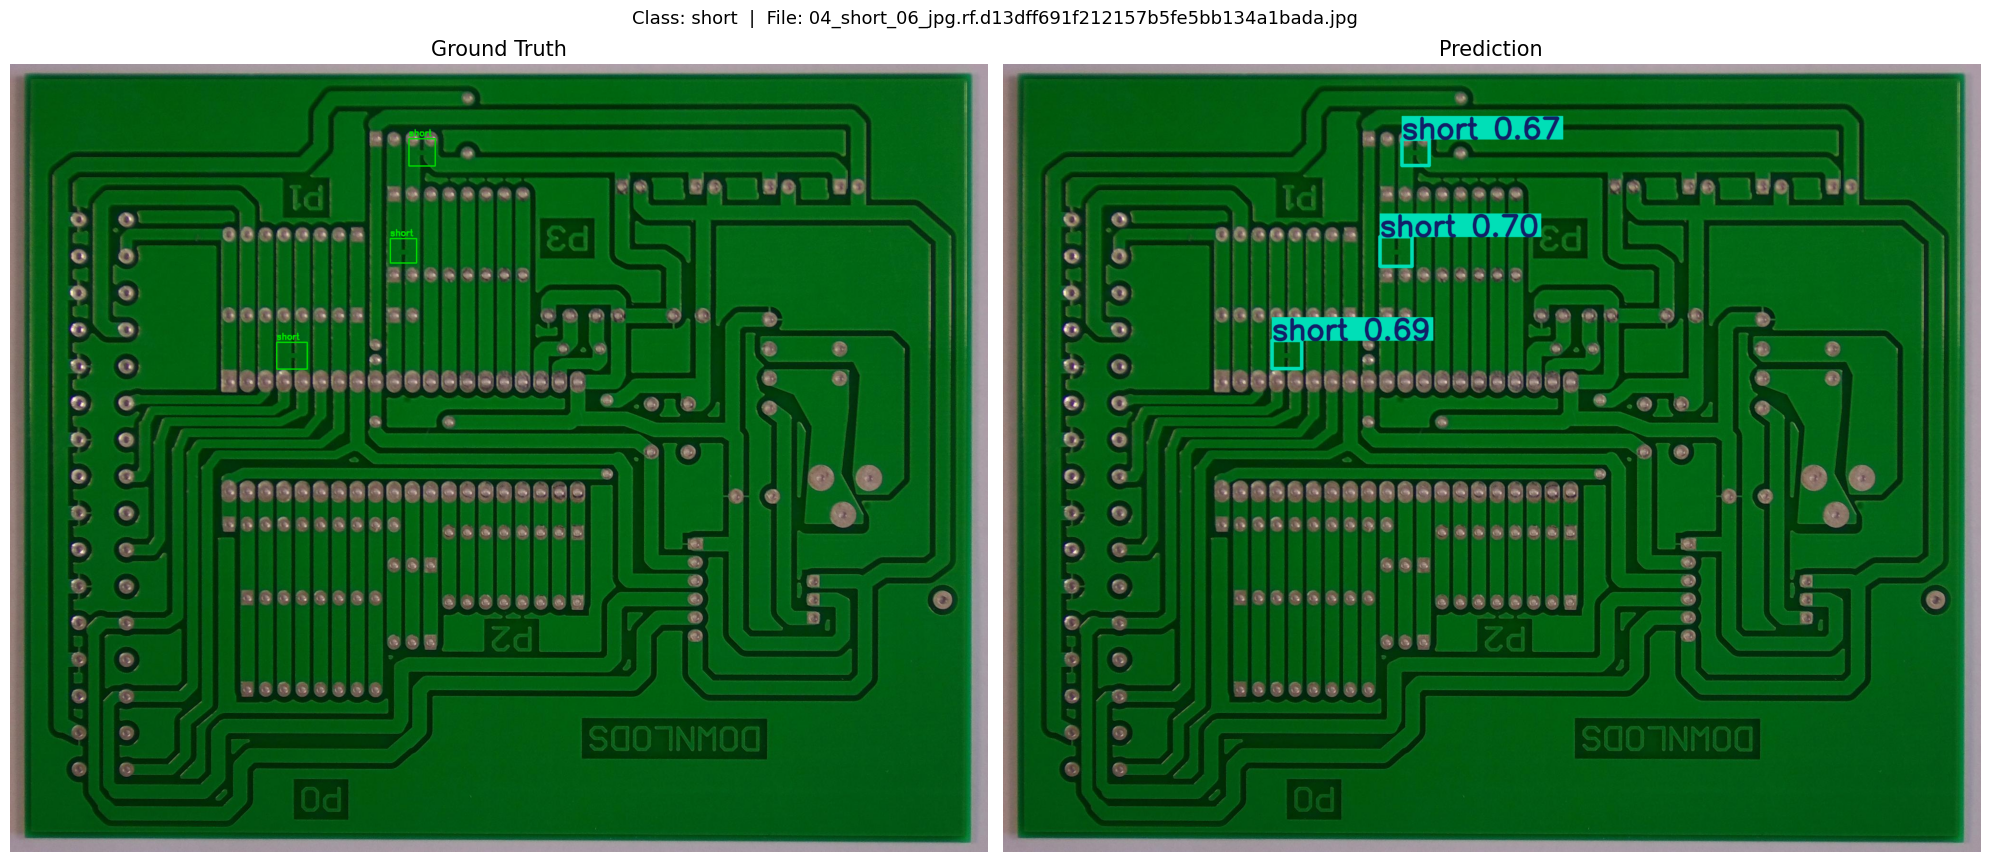

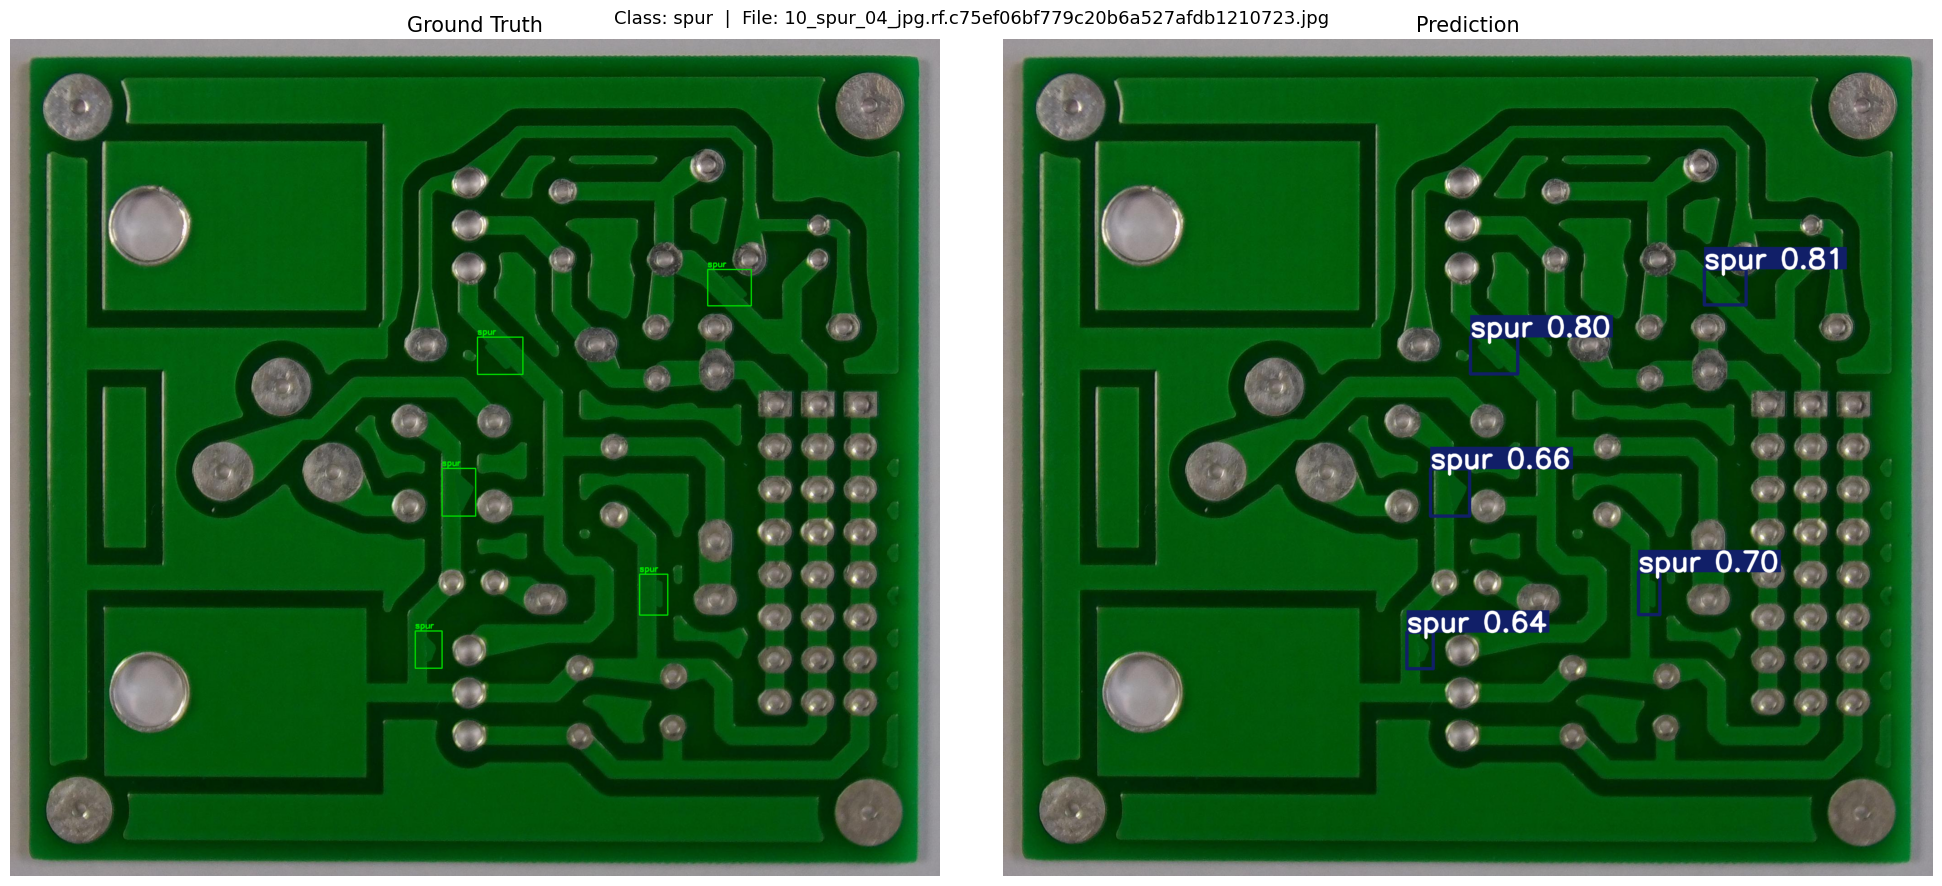

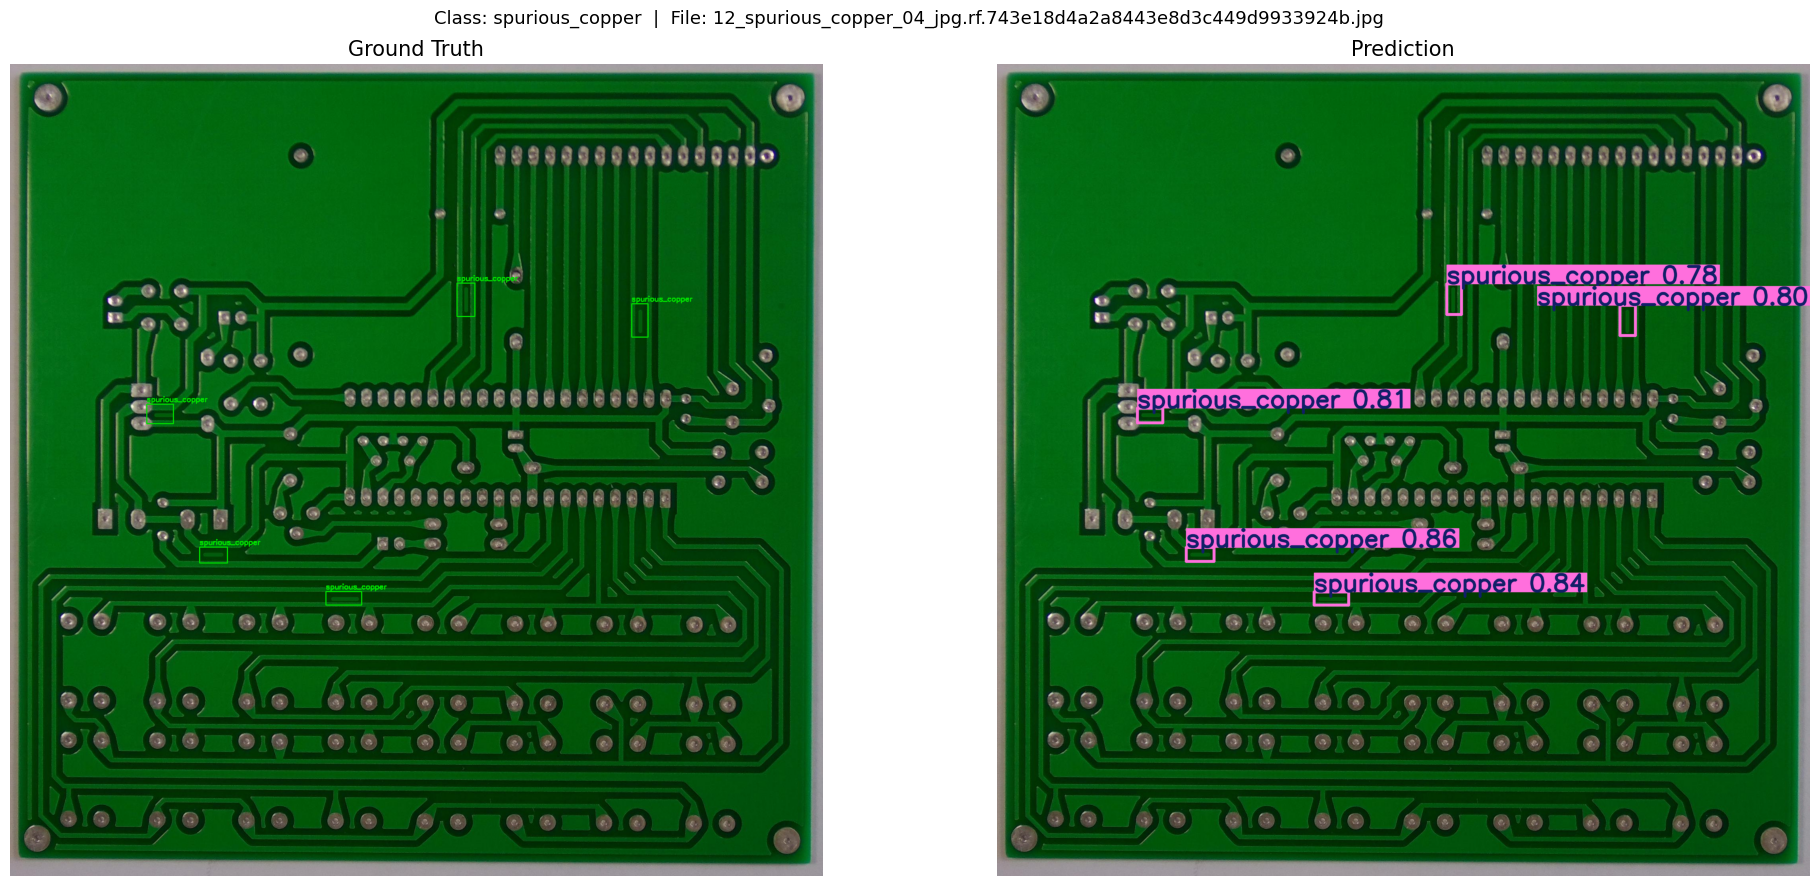

In [14]:
import os
import glob
import random
import cv2
import matplotlib.pyplot as plt

split_dir = "/content/pcb-defect-detection-1/valid"
image_files = sorted(glob.glob(f"{split_dir}/images/*"))

class_names = best_model.names  # {0: '...', 1: '...', ...}

def get_label_path(img_path):
    base_name = os.path.splitext(os.path.basename(img_path))[0]
    return os.path.join(os.path.dirname(os.path.dirname(img_path)), "labels", f"{base_name}.txt")

images_by_class = {cls_id: [] for cls_id in class_names}

for img_path in image_files:
    lbl_path = get_label_path(img_path)
    if os.path.exists(lbl_path):
        with open(lbl_path, "r") as f:
            present_classes = set()
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    present_classes.add(int(parts[0]))
            for cls_id in present_classes:
                if cls_id in images_by_class:
                    images_by_class[cls_id].append(img_path)

selected_samples = []
for cls_id, cls_name in class_names.items():
    candidates = images_by_class.get(cls_id, [])
    if candidates:
        chosen_img = random.choice(candidates)
        selected_samples.append((cls_id, cls_name, chosen_img))
    else:
        print(f"There is no img: {cls_name} in {split_dir}")

def draw_ground_truth(img_path, names):
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img_rgb.shape

    label_path = get_label_path(img_path)
    if os.path.exists(label_path):
        with open(label_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    cls_id = int(parts[0])
                    xc, yc, bw, bh = map(float, parts[1:5])

                    x1 = int((xc - bw / 2) * w)
                    y1 = int((yc - bh / 2) * h)
                    x2 = int((xc + bw / 2) * w)
                    y2 = int((yc + bh / 2) * h)

                    label_text = names.get(cls_id, str(cls_id))
                    cv2.rectangle(img_rgb, (x1, y1), (x2, y2), (0, 220, 0), 2)
                    cv2.putText(
                        img_rgb,
                        label_text,
                        (x1, max(y1 - 6, 15)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.6,
                        (0, 220, 0),
                        2
                    )
    return img_rgb


chosen_paths = [item[2] for item in selected_samples]
preds = best_model.predict(
    source=chosen_paths,
    imgsz=640,
    conf=0.40,
    save=False
)

for (cls_id, cls_name, img_path), res in zip(selected_samples, preds):
    gt_img = draw_ground_truth(img_path, class_names)
    pred_img = cv2.cvtColor(res.plot(), cv2.COLOR_BGR2RGB)

    fig, axes = plt.subplots(1, 2, figsize=(20, 9))

    axes[0].imshow(gt_img)
    axes[0].set_title("Ground Truth", fontsize=15)
    axes[0].axis("off")

    axes[1].imshow(pred_img)
    axes[1].set_title("Prediction", fontsize=15)
    axes[1].axis("off")

    plt.suptitle(f"Class: {cls_name}  |  File: {os.path.basename(img_path)}", fontsize=13)
    plt.tight_layout()
    plt.show()

In [18]:
import os
import shutil
from google.colab import files

export_dir = "/content/selected_raw_pcb_images"
os.makedirs(export_dir, exist_ok=True)

for cls_id, cls_name, img_path in selected_samples:
    ext = os.path.splitext(img_path)[1]

    clean_name = os.path.basename(img_path)
    dest_name = f"{cls_name}_{clean_name}" if not clean_name.startswith(cls_name) else clean_name
    shutil.copy2(img_path, os.path.join(export_dir, dest_name))


zip_path = "/content/selected_raw_pcb_images"
shutil.make_archive(zip_path, "zip", export_dir)
files.download(f"{zip_path}.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
from google.colab import files
files.download("/content/runs/detect/pcb_project/yolo26s_exp1/weights/best.pt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import importlib.metadata as md

def v(name):
    try:
        return md.version(name)
    except md.PackageNotFoundError:
        return None

lines = [
    f"ultralytics=={v('ultralytics')}",
    "opencv-python-headless",
    "streamlit",
    "pillow",
]

with open("requirements.txt", "w") as f:
    f.write("\n".join(lines) + "\n")

print(open("requirements.txt").read())

ultralytics==8.4.220
opencv-python-headless
streamlit
pillow

